# Parte D — LGD: variable objetivo, preprocesamiento, lineal frente a MLP y distribuciones

Capa delgada sobre `src/` (núcleo §5.8): el notebook no calcula nada por su cuenta, solo llama funciones del
repositorio y muestra sus resultados. **Se edita este `.py`; el `.ipynb` lo genera `python run.py notebooks`.**

Lee `results/data/lgd/resumen_objetivo.json`, `descriptivo.json` y `summary.json`, los datos procesados de la LGD
(`data/processed/loans_lgd.parquet`, `models/preprocesador_lgd.json`, tal cual) y las figuras ya versionadas de
`blog/docs/figures/lgd-*.png`. La demo en vivo entrena en una **carpeta temporal** (resultados y modelos): el notebook
no escribe en `data/processed/`, `models/`, `results/`, `configs/lgd/mlp_final.yaml` ni `blog/`.

Para la modificación en vivo, cambia `SET` (mismas claves que `--set`) y corre todo. Ejemplos:

- otra arquitectura: `SET = {"mlp.capas": [128, 64, 32]}`
- más regularización: `SET = {"mlp.dropout": 0.3}`
- otra pérdida: `SET = {"mlp.perdida": "mse"}`
- más semillas o más datos: `SET = {"semillas.n": 5, "datos.muestra": 5000}`

Los resultados reportados (30 semillas, configuración de la búsqueda) son otro comando:
`python run.py lgd --config configs/lgd/base.yaml`.

In [1]:
CONFIG = "configs/lgd/demo.yaml"
SET = {}

In [2]:
import tempfile
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from src.common.config import load_config
from src.common.notebooks import config_notebook
from src.common.results import load_json
from src.viz.figs_lgd import SALIDA as FIGURAS_BLOG

CONFIG_OFICIAL = "configs/lgd/base.yaml"  # solo para leer dónde están los resultados reportados (sección 5)
pd.set_option("display.width", 160)

cfg = config_notebook(CONFIG, SET)

Configuración final resuelta:
mlp:
  capas:
  - 64
  - 32
  activacion: relu
  dropout: 0.1
  l2: 0.0001
  optimizador: adam
  lr: 0.001
  momento: 0.9
  batch: 256
  max_epocas: 30
  paciencia: 5
  device: auto
  perdida: bce_fraccional
busqueda:
  tipo: sin_busqueda
  origen: 'demo: valores de partida de D3 (no usa la búsqueda)'
  ensayo: null
  n_ensayos: null
  tiempo_s: null
  hash_particion: null
  hash_preprocesador: null
  muestra: null
  fecha: null
datos:
  config_datos: configs/datos.yaml
  loans_pd: data/processed/loans_pd.parquet
  montos: data/processed/montos.parquet
  salida:
    loans_lgd: data/processed/loans_lgd.parquet
    preprocesador: models/preprocesador_lgd.json
    resumen: results/data/lgd/resumen_objetivo.json
  muestra: 20000
base_seed: 0
semillas:
  n: 3
hpo:
  n_ensayos: 5
  destino: results/data/lgd_demo/mlp_final.yaml
  espacio:
    n_capas:
    - 1
    - 4
    neuronas:
    - 16
    - 32
    - 64
    - 128
    - 256
    activacion:
    - relu
    - lea

## 1. Variable objetivo observada (resultados versionados de D1 y D1b)

LGD = 1 − (`recoveries` − `collection_recovery_fee`) / EAD, con EAD = `funded_amnt` − `total_rec_prncp`, recortada a
[0, 1], sobre los créditos castigados (Parte D §3.2). Población, exclusiones, masa en 0 y en 1 y casos recortados:

In [3]:
from src.lgd.tablas import tabla_poblacion, tabla_por_anio, tabla_por_plazo, tabla_por_split

resumen_objetivo = load_json(cfg["datos"]["salida"]["resumen"])
descriptivo = load_json(cfg["descriptivo"]["salida"])
obs = descriptivo["observado"]
tabla_poblacion(resumen_objetivo)

,valor
créditos en loans_pd,237695
población LGD,43236
población: Charged Off,42475
población: Does not meet the credit policy. Status:Charged Off,761
excluidos: Default,832
excluidos: Late (31-120 days),6900
fuera de la población: Fully Paid,184739
fuera de la población: Does not meet the credit policy. Status:Fully Paid,1988
EAD ≤ 0 (excluidos),0
LGD = 0,36


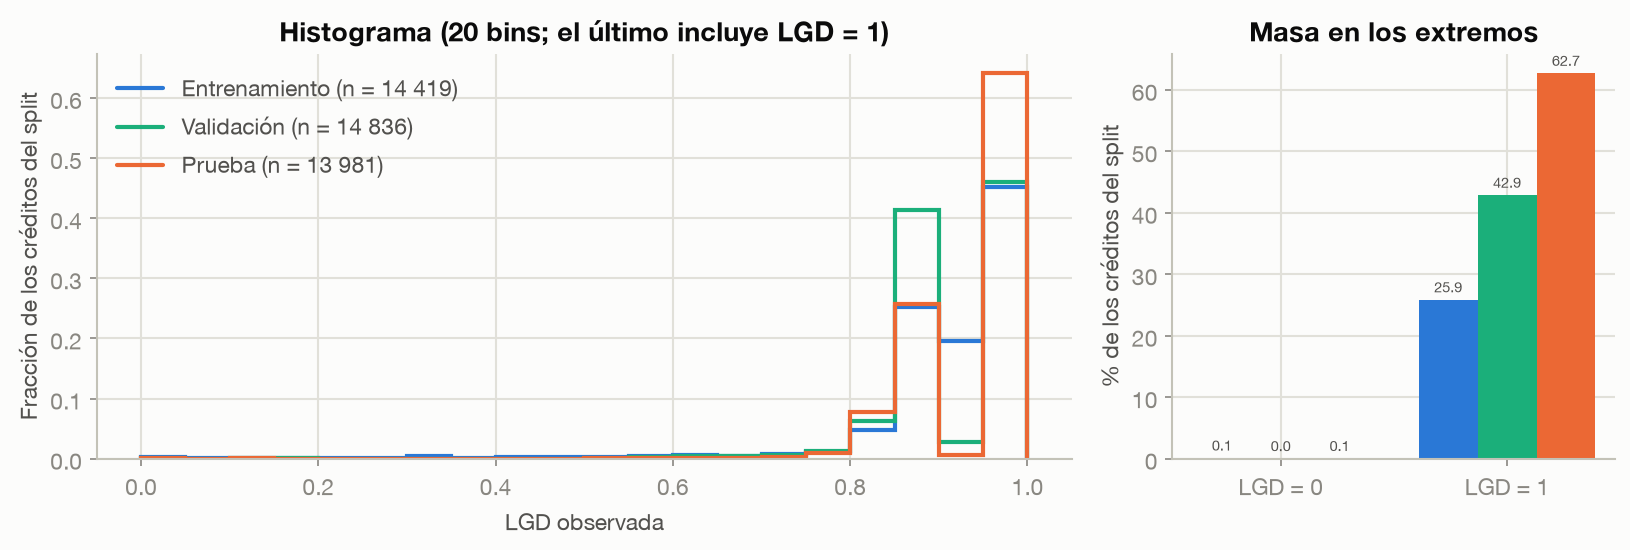

In [4]:
display(Image(filename=str(FIGURAS_BLOG / "lgd-histograma.png")))

### LGD por partición y por año de originación

In [5]:
tabla_por_split(obs).round(3)

,créditos,LGD media,LGD mediana,fracción LGD = 1,fracción LGD = 0,EAD mediana
train,14419,0.917,0.943,0.259,0.001,6835.60
val,14836,0.918,0.884,0.429,0.000,9477.28
test,13981,0.945,1.000,0.627,0.001,11180.27


In [6]:
tabla_por_anio(obs).round(3)

,split,créditos,LGD media,LGD mediana,fracción LGD = 1,fracción LGD = 0,EAD mediana
2007,train,158,0.921,0.955,0.367,0.006,4168.630
2008,train,496,0.931,0.977,0.442,0.002,4886.905
2009,train,723,0.926,0.956,0.340,0.001,5637.740
2010,train,1753,0.925,0.955,0.256,0.001,5116.360
2011,train,3205,0.922,0.943,0.227,0.002,6839.020
2012,train,8084,0.911,0.943,0.252,0.001,7699.425
2013,val,14836,0.918,0.884,0.429,0.000,9477.280
2014,test,13981,0.945,1.000,0.627,0.001,11180.270


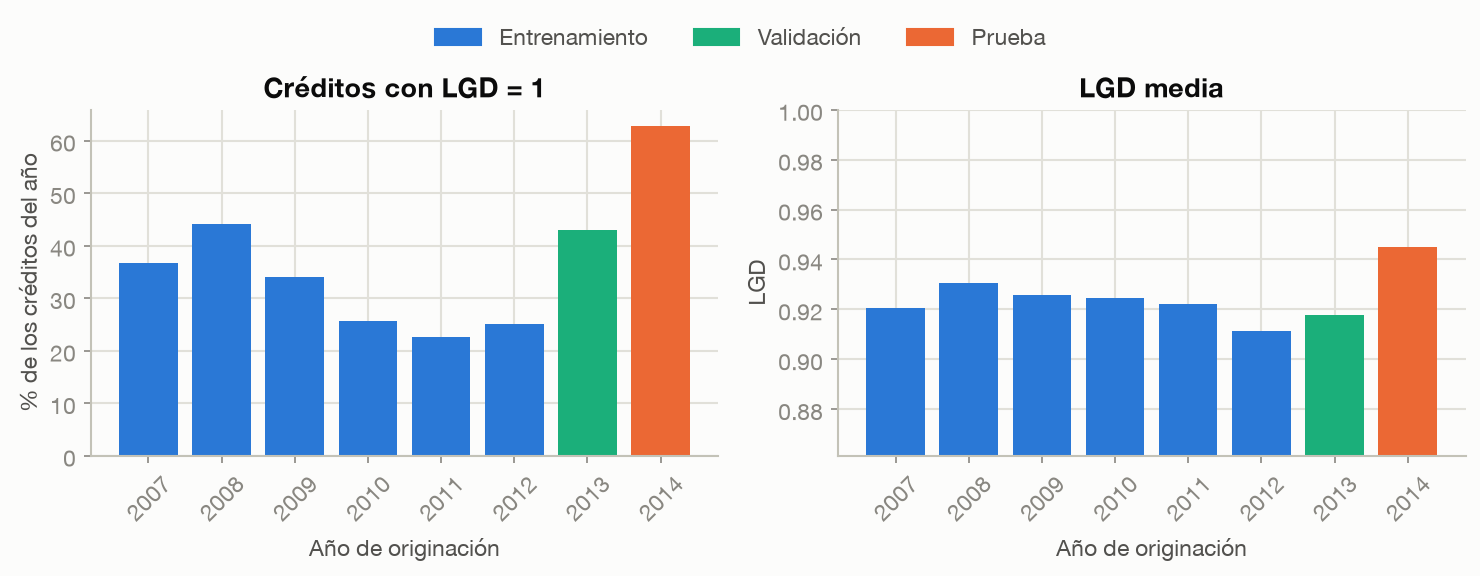

In [7]:
display(Image(filename=str(FIGURAS_BLOG / "lgd-por-anio.png")))

La distribución de la LGD cambia entre particiones (la fracción con LGD = 1 crece en validación y en prueba). Se
acepta y se documenta como limitación (Parte D §3.2): en 2013–2014 es **consistente con censura** (recuperaciones
todavía abiertas en los castigos recientes), no una causa probada; tampoco se descartan composición ni cambios de
cobranza.

### EAD y LGD por plazo

In [8]:
tabla_por_plazo(obs).round(3)

,créditos,LGD media,LGD mediana,fracción LGD = 1,fracción LGD = 0,EAD mediana
36 months,28104,0.927,0.955,0.448,0.001,6544.040
60 months,15132,0.925,0.952,0.415,0.001,15704.795


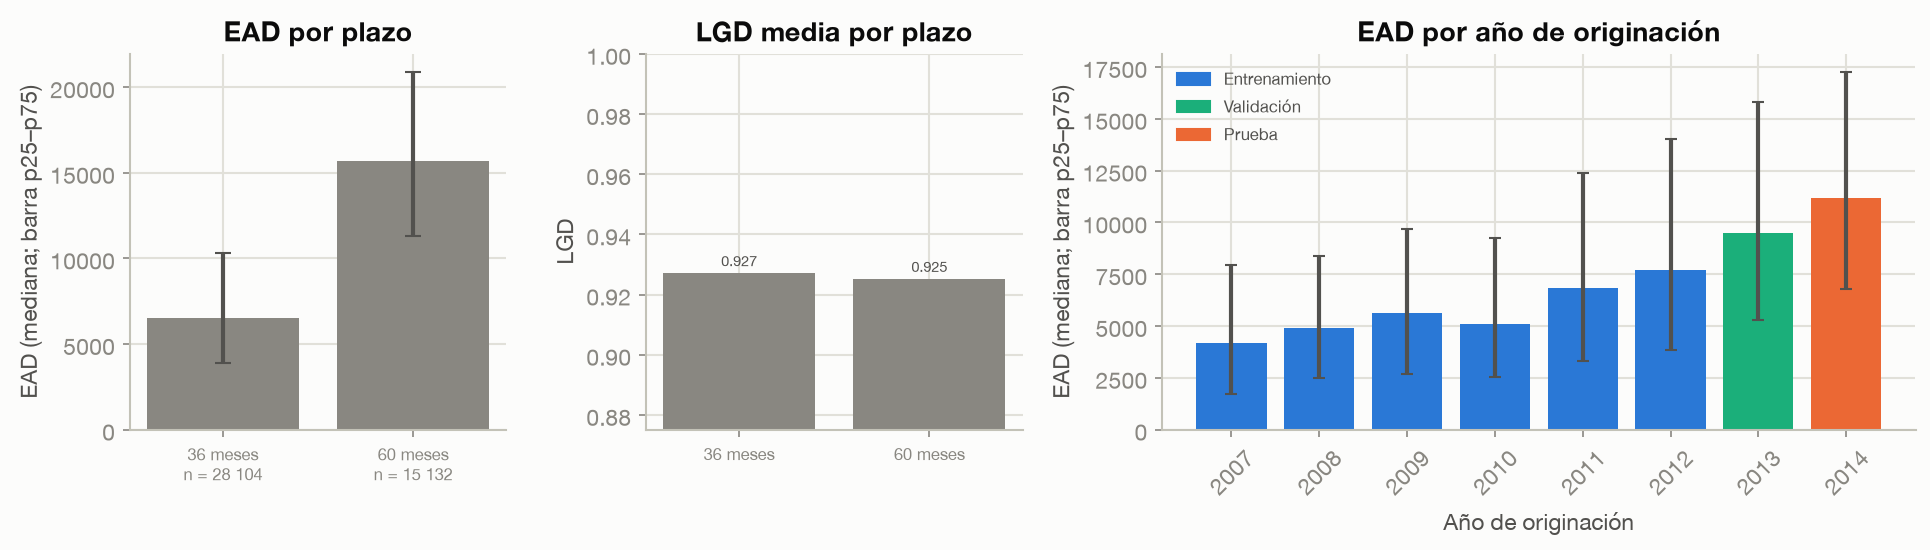

In [9]:
display(Image(filename=str(FIGURAS_BLOG / "lgd-ead-plazo.png")))

## 2. Después del preprocesamiento (funciones de la Parte A sobre la población de la LGD)

Efecto de las transformaciones (fracción de filas imputadas o recortadas en las numéricas; desconocidas o llevadas a
OTRA en las categóricas), estabilidad entre particiones (PSI frente a train) y relación de cada variable con la LGD.

In [10]:
from src.lgd.tablas import tabla_efecto_transformaciones, tabla_psi, tabla_relacion_objetivo

pre = descriptivo["preprocesado"]
tabla_efecto_transformaciones(pre).round(3)

train                                                          val                                                         test  \
                         imputado recortado_abajo recortado_arriba desconocido a_otra imputado recortado_abajo recortado_arriba desconocido a_otra imputado   
loan_amnt                   0.000           0.010            0.000         NaN    NaN      0.0           0.003            0.000         NaN    NaN    0.000   
term                          NaN             NaN              NaN       0.000    0.0      NaN             NaN              NaN       0.000    0.0      NaN   
emp_length                    NaN             NaN              NaN       0.042    0.0      NaN             NaN              NaN       0.055    0.0      NaN   
home_ownership                NaN             NaN              NaN       0.000    0.0      NaN             NaN              NaN       0.000    0.0      NaN   
annual_inc                  0.000           0.010            0.010         NaN    NaN      0.0           0.004            0.009         NaN    NaN    0.000   
purpose                       NaN             NaN              NaN       0.000    0.0      NaN             NaN              NaN       0.000    0.0      NaN   
dti                         0.000           0.010            0.010         NaN    NaN      0.0           0.002            0.022         NaN    NaN    0.000   
delinq_2yrs                 0.000           0.000            0.005         NaN    NaN      0.0           0.000            0.008         NaN    NaN    0.000   
antiguedad_credito_anios    0.000           0.010            0.010         NaN    NaN      0.0           0.002            0.013         NaN    NaN    0.000   
inq_last_6mths              0.000           0.000            0.007         NaN    NaN      0.0           0.000            0.000         NaN    NaN    0.000   
open_acc                    0.000           0.001            0.008         NaN    NaN      0.0           0.000            0.012         NaN    NaN    0.000   
pub_rec                     0.000           0.000            0.001         NaN    NaN      0.0           0.000            0.012         NaN    NaN    0.000   
revol_bal                   0.000           0.000            0.010         NaN    NaN      0.0           0.000            0.006         NaN    NaN    0.000   
revol_util                  0.002           0.000            0.010         NaN    NaN      0.0           0.000            0.007         NaN    NaN    0.001   
total_acc                   0.000           0.006            0.010         NaN    NaN      0.0           0.001            0.013         NaN    NaN    0.000   

                                                                              
                         recortado_abajo recortado_arriba desconocido a_otra  
loan_amnt                          0.003            0.000         NaN    NaN  
term                                 NaN              NaN       0.000    0.0  
emp_length                           NaN              NaN       0.066    0.0  
home_ownership                       NaN              NaN       0.000    0.0  
annual_inc                         0.004            0.011         NaN    NaN  
purpose                              NaN              NaN       0.000    0.0  
dti                                0.002            0.048         NaN    NaN  
delinq_2yrs                        0.000            0.017         NaN    NaN  
antiguedad_credito_anios           0.003            0.017         NaN    NaN  
inq_last_6mths                     0.000            0.000         NaN    NaN  
open_acc                           0.001            0.026         NaN    NaN  
pub_rec                            0.000            0.029         NaN    NaN  
revol_bal                          0.000            0.007         NaN    NaN  
revol_util                         0.000            0.012         NaN    NaN  
total_acc                          0.000            0.018   

In [11]:
tabla_psi(pre).round(3)

,val,test
purpose,0.206,0.322
dti,0.147,0.227
pub_rec,0.044,0.158
inq_last_6mths,0.128,0.126
open_acc,0.086,0.105
antiguedad_credito_anios,0.054,0.078
total_acc,0.051,0.074
loan_amnt,0.075,0.074
delinq_2yrs,0.008,0.056
revol_util,0.068,0.051


In [12]:
tabla_relacion_objetivo(pre).round(3)

,ρ (Spearman por grupos),n_grupos,monótona,LGD media grupo bajo,LGD media grupo alto
loan_amnt,-0.479,10,False,0.915,0.906
annual_inc,-0.770,10,False,0.920,0.900
dti,-0.139,10,False,0.916,0.915
delinq_2yrs,-0.800,4,False,0.918,0.899
antiguedad_credito_anios,-0.467,10,False,0.916,0.910
inq_last_6mths,1.000,4,True,0.915,0.932
open_acc,-0.115,10,False,0.916,0.914
pub_rec,1.000,2,True,0.916,0.935
revol_bal,0.152,10,False,0.913,0.916
revol_util,-0.442,10,False,0.922,0.915


In [13]:
for clave, nota in pre["notas_objetivo_continuo"].items():
    print(f"- {clave}: {nota}")

- tasa_objetivo_por_split: con objetivo continuo es la LGD media por split (el nombre viene de la Parte A, PD)
- relacion_con_objetivo_train: tasa_grupo_bajo/alto y tasas_por_grupo son LGD media por grupo (decil o valor) de la variable transformada en train; spearman_grupos y monotona igual que en A
- monotona_con_dos_grupos: con n_grupos == 2, monotona es siempre verdadera (ρ = signo de la diferencia entre los dos grupos; src/datos/eda.py:74-75) y no es evidencia de relación (caso pub_rec)
- categoricas_sin_relacion: descriptivo_post mide la relación con el objetivo solo para las numéricas; las categóricas emp_length, home_ownership y purpose no están cubiertas (term se cubre con observado.por_plazo)


Dos cautelas que trae el propio `descriptivo.json` (notas de arriba): con `n_grupos == 2`, "monótona" es
siempre verdadera y **no es evidencia** de relación; y las categóricas no tienen relación medida con la LGD (el
plazo se ve en la tabla por plazo de la sección 1).

## 3. Demo en vivo: lineal frente a MLP (config demo, carpeta temporal)

Muestra, semillas y épocas reducidas para que corra en < 2 min: **no son los resultados reportados** (sección 5).
La salida y los modelos **siempre van a la carpeta temporal**, aunque se cambien `salida` o `modelos.*` en `SET`.

In [14]:
from src.lgd.experimento import entrenar_semillas
from src.lgd.tablas import redirigir_salidas, tabla_metricas_compacta

carpeta_demo = Path(tempfile.mkdtemp(prefix="demo_lgd_"))
inicio = time.perf_counter()
resumen_demo = entrenar_semillas(redirigir_salidas(cfg, carpeta_demo))
print(f"Tiempo de la demo: {time.perf_counter() - inicio:.1f} s · créditos: {resumen_demo['n']} · "
      f"configuración del MLP: {resumen_demo['busqueda']['origen']}")
tabla_metricas_compacta(resumen_demo)

Tiempo de la demo: 1.3 s · créditos: {'train': 6670, 'val': 6863, 'test': 6467} · configuración del MLP: demo: valores de partida de D3 (no usa la búsqueda)


,MAE val,RMSE val,MAE test,RMSE test,semillas,parámetros,configuraciones,tiempo (s)
lineal,0.0756,0.0934,0.0778,0.0879,1,49,1,0.0
mlp,0.0759 ± 0.0001,0.0940 ± 0.0002,0.0772 ± 0.0006,0.0877 ± 0.0007,3,5249,1,0.9
constante_media,0.0765,0.0932,0.0779,0.0865,1,1,1,—
constante_mediana,0.0774,0.0966,0.0701,0.0816,1,1,1,—


## 4. Distribuciones de la demo (las figuras del blog, dibujadas con esta corrida en la carpeta temporal)

findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


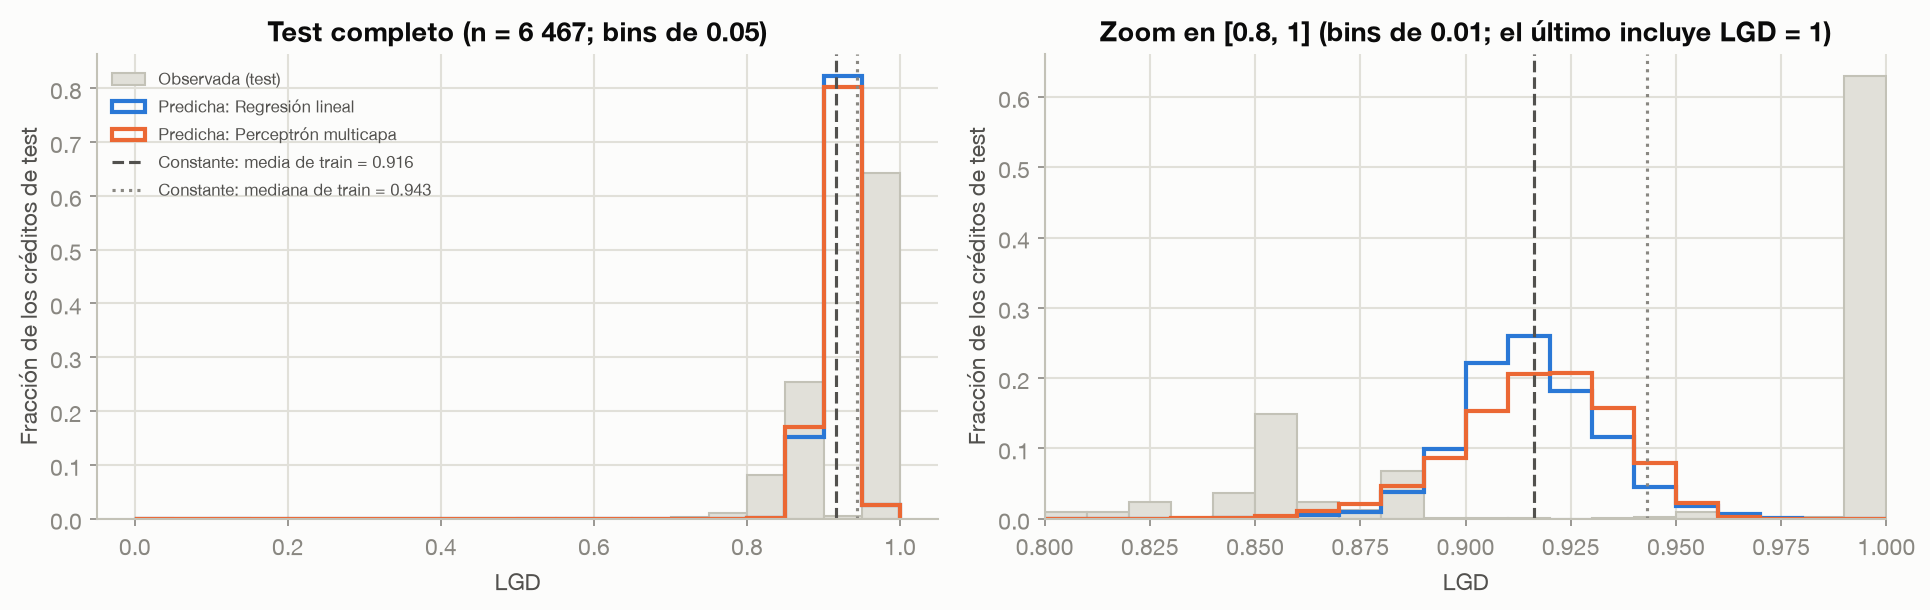

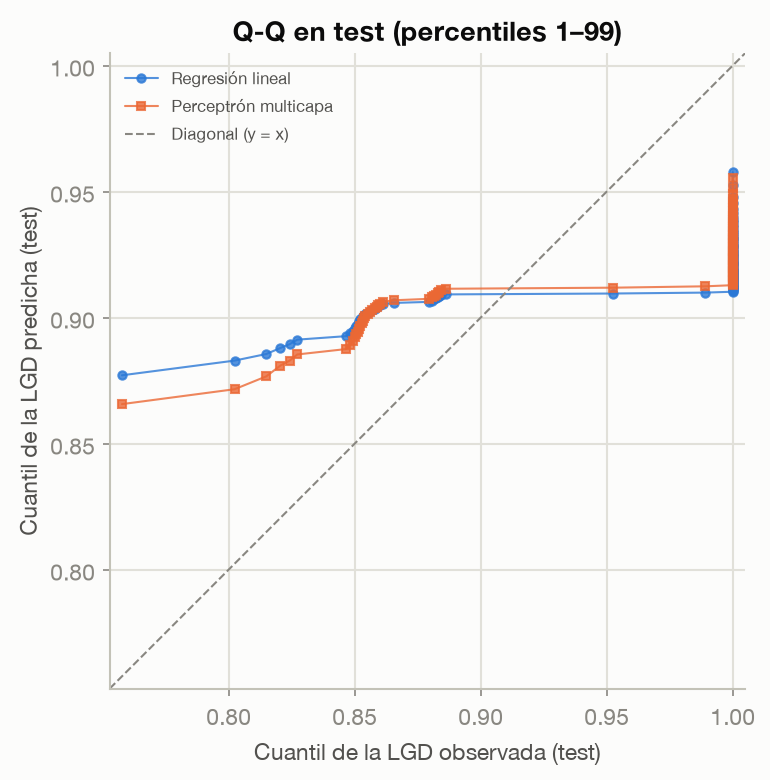

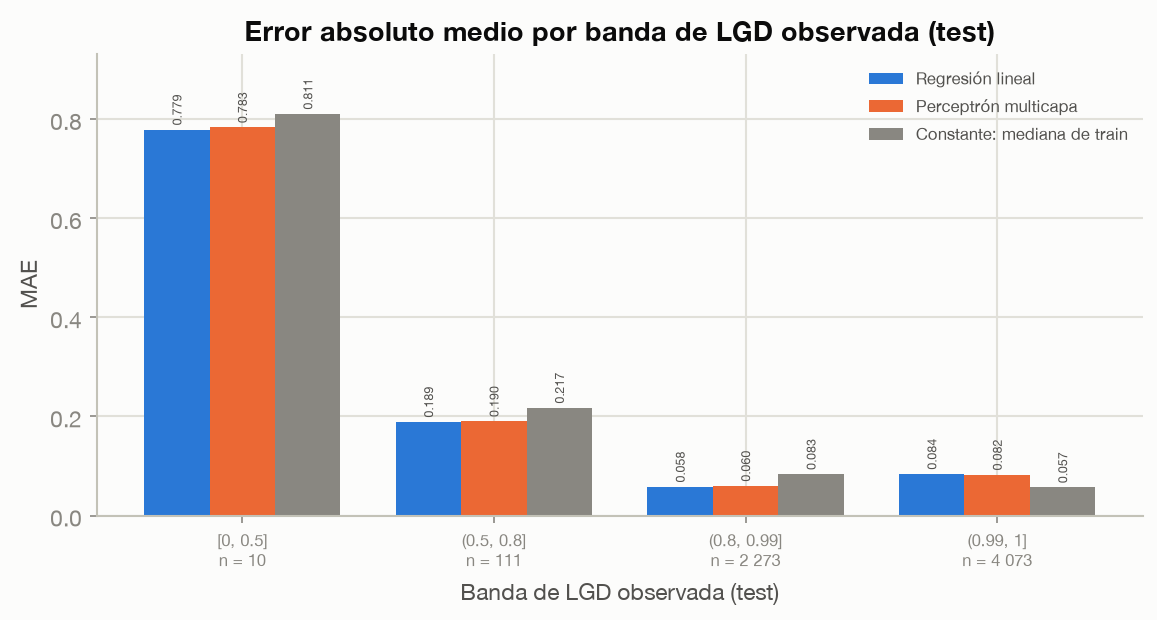

In [15]:
from src.viz.figs_lgd import generar, insumos_de_corrida

figuras_demo = {r.name: r for r in generar(destino=carpeta_demo / "figuras",
                                           datos=insumos_de_corrida(carpeta_demo, obs))}
for nombre in ("lgd-distribucion-predicha.png", "lgd-qq.png", "lgd-error-por-banda.png"):
    display(Image(filename=str(figuras_demo[nombre])))

## 5. Resultados oficiales (leídos de `summary.json` de la config oficial, sin entrenar)

In [16]:
from src.lgd.tablas import comparacion, tabla_referencias

resumen = load_json(Path(load_config(CONFIG_OFICIAL)["salida"]) / "summary.json")
mlp = resumen["modelos"]["mlp"]
print(f"Configuración del MLP: {resumen['busqueda']['origen']}")
print(f"Capas {mlp['config']['mlp']['capas']} · pérdida {mlp['config']['mlp']['perdida']} · "
      f"búsqueda {mlp['tiempo_busqueda_s']:.1f} s · semillas {mlp['tiempo_semillas_s']:.1f} s")
tabla_metricas_compacta(resumen)

Configuración del MLP: lgd-hpo: mejor de 30 ensayos (mínima pérdida de validación del propio MLP (media de mlp.perdida en val, mejor época); MAE de val al lado [PROPUESTO por el orquestador])
Capas [128, 64] · pérdida bce_fraccional · búsqueda 32.5 s · semillas 13.1 s


,MAE val,RMSE val,MAE test,RMSE test,semillas,parámetros,configuraciones,tiempo (s)
lineal,0.0759,0.0928,0.0771,0.0866,1,49,1,0.0
mlp,0.0762 ± 0.0002,0.0925 ± 0.0001,0.0771 ± 0.0006,0.0857 ± 0.0008,30,14593,30,45.6
constante_media,0.0764,0.0925,0.0775,0.0859,1,1,1,—
constante_mediana,0.0772,0.0959,0.0699,0.0811,1,1,1,—


In [17]:
for metrica in ("mae_test", "rmse_test"):
    c = comparacion(resumen, metrica)
    print(f"{metrica} del MLP (media de {mlp['metricas'][metrica]['n']} semillas): "
          f"{c['valores']['mlp']:.4f} ± {c['desv_mlp']:.4f}")
    for otro, diferencia in c["mlp_menos"].items():
        print(f"  MLP − {otro} ({c['valores'][otro]:.4f}): {diferencia:+.5f}")
    print(f"  menor {metrica}: {c['mejor']}")

mae_test del MLP (media de 30 semillas): 0.0771 ± 0.0006
  MLP − lineal (0.0771): -0.00004
  MLP − constante_media (0.0775): -0.00041
  MLP − constante_mediana (0.0699): +0.00722
  menor mae_test: constante_mediana
rmse_test del MLP (media de 30 semillas): 0.0857 ± 0.0008
  MLP − lineal (0.0866): -0.00089
  MLP − constante_media (0.0859): -0.00021
  MLP − constante_mediana (0.0811): +0.00455
  menor rmse_test: constante_mediana


In [18]:
tabla_referencias(resumen).round(4)

,valor (de train)
constante_media,0.9169
constante_mediana,0.9432


Lectura: las diferencias de arriba (MLP menos cada alternativa) dicen si la red aportó algo frente a la regresión
lineal y frente a predecir una constante (media o mediana de la LGD de train, `summary.json` → `referencias`); un
signo negativo es a favor del MLP. Dos hechos para leerlas, sin afirmar causas:

- Entre las constantes, la **mediana** es la que minimiza el error absoluto esperado (por eso es la referencia natural
  para el MAE), mientras que el MLP se entrena con la pérdida impresa arriba; con `bce_fraccional` su minimizador
  poblacional es la **media** condicional (`src/lgd/perdidas.py`).
- La LGD de test está desplazada hacia 1 frente a train (tabla por partición de la sección 1), lo que favorece a una
  constante alta (los valores de las dos constantes están en la tabla de arriba).

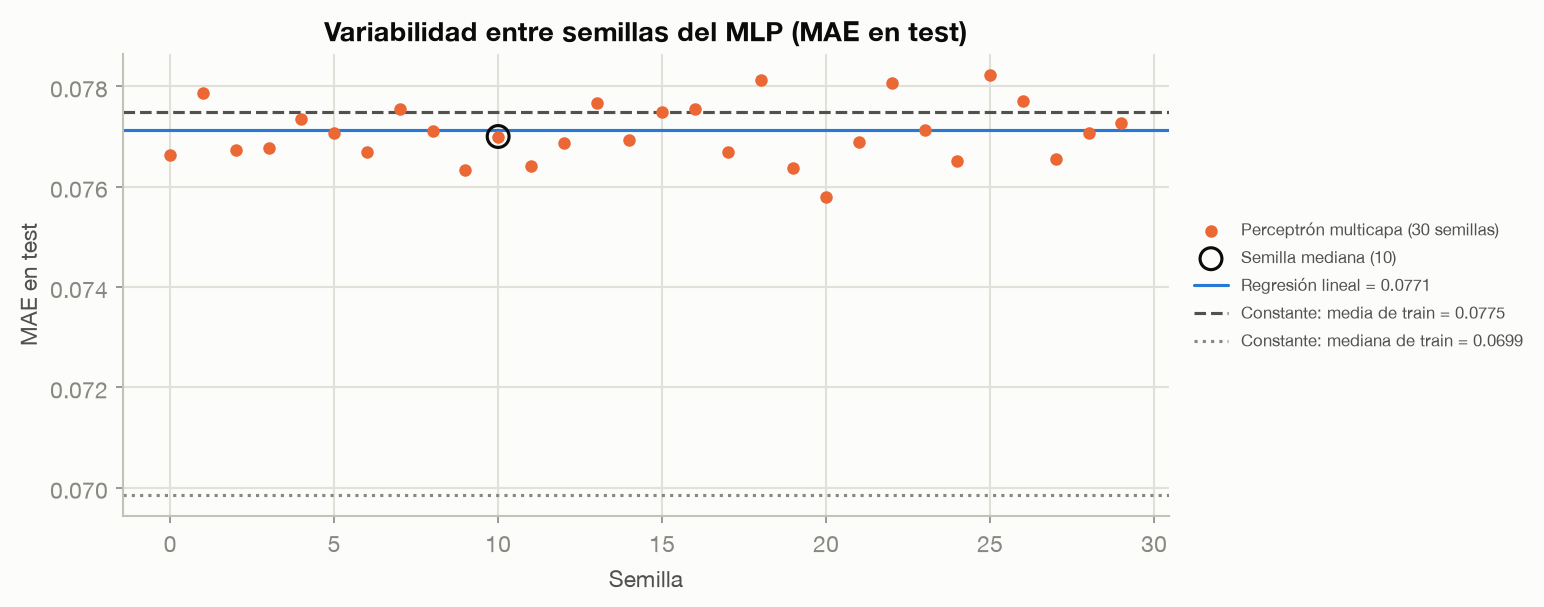

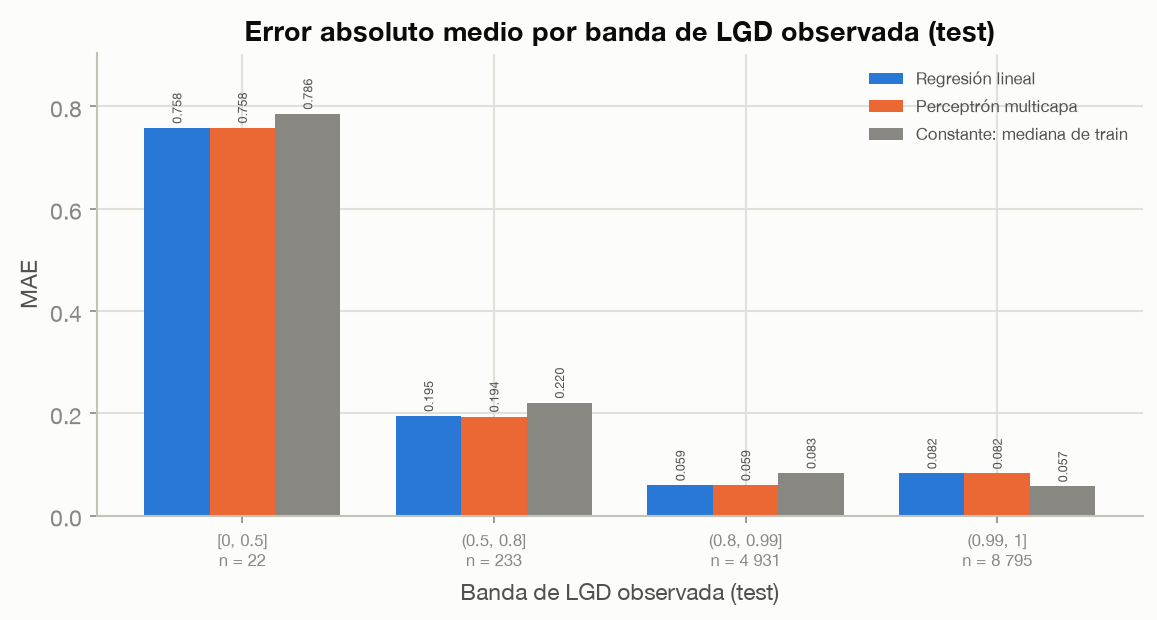

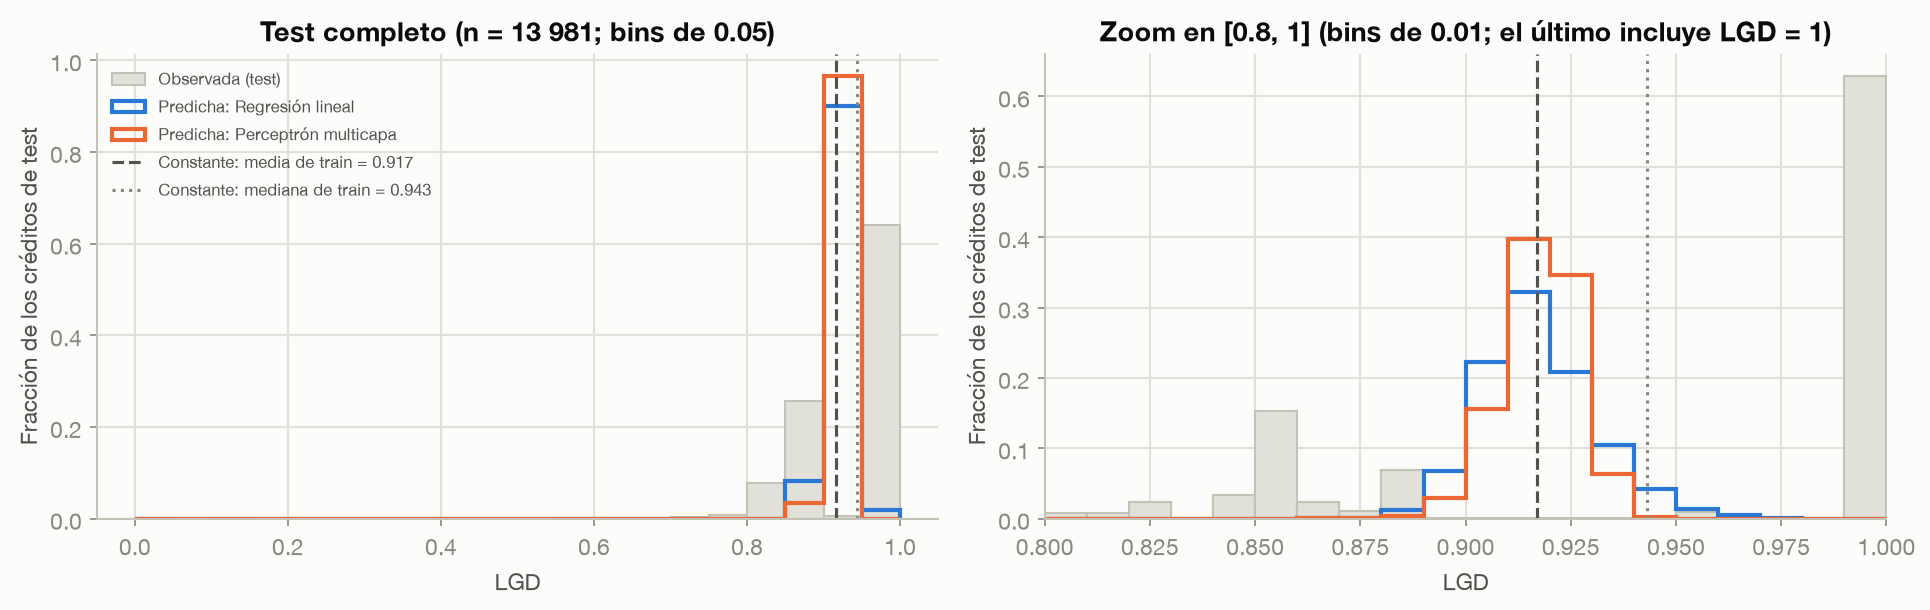

In [19]:
for nombre in ("lgd-semillas.png", "lgd-error-por-banda.png", "lgd-distribucion-predicha.png"):
    display(Image(filename=str(FIGURAS_BLOG / nombre)))